## Homework #1
* 목표: 영화 평균 평점 예측
* 최종 목표: 영화의 개봉 전 정보를 이용해 평균 평점을 예측하고, 영화의 장르·언어·개봉 시기 등에 따른 평점 경향을 분석한다.
* 지도 학습 + 회귀 작업 + 배치 학습

## 1. 데이터 읽기

In [218]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("Top Movies dataset.csv")

if not DATA_PATH.is_file():
    print("동일 폴더 내에 csv 파일이 존재하지 않습니다.")

movies = pd.read_csv(DATA_PATH)

## 2. 데이터 구조 살피기

In [219]:
movies.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url,Working URL
0,15/12/2021,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...,https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,01/03/2022,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...,https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,25/02/2022,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,24/11/2021,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...,https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,22/12/2021,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...,https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


In [220]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9837 non-null   str    
 1   Title              9828 non-null   str    
 2   Overview           9828 non-null   str    
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9827 non-null   str    
 5   Vote_Average       9827 non-null   str    
 6   Original_Language  9827 non-null   str    
 7   Genre              9826 non-null   str    
 8   Poster_Url         9826 non-null   str    
 9   Working URL        9837 non-null   str    
dtypes: float64(1), str(9)
memory usage: 768.6 KB


In [221]:
movies.describe(include="all")

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url,Working URL
count,9837,9828,9828,9827.000000,9827,9827,9827,9826,9826,9837
unique,5903,9514,9823,NaN,3267,75,44,2337,9826,9827
top,10/03/2022,Beauty and the Beast,"Alien pods come to Earth and, naturally, start...",NaN,0,6.4,en,Drama,https://image.tmdb.org/t/p/original/1g0dhYtq4i...,0
freq,16,4,2,NaN,100,435,7569,466,1,11
mean,NaN,NaN,NaN,40.320672,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,108.875673,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,7.100000,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,16.127500,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,21.191000,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,35.174500,NaN,NaN,NaN,NaN,NaN,NaN


In [222]:
movies.isna().sum()

Release_Date          0
Title                 9
Overview              9
Popularity           10
Vote_Count           10
Vote_Average         10
Original_Language    10
Genre                11
Poster_Url           11
Working URL           0
dtype: int64

In [223]:
from IPython.display import display

converted = pd.to_numeric(movies["Vote_Average"], errors="coerce")
bad = movies["Vote_Average"].notna() & converted.isna()

print("Vote_Average 숫자로 변환 불가능한 값:", int(bad.sum()))

if bad.sum() > 0:
    display(movies.loc[bad, ["Title", "Vote_Average"]].head())

Vote_Average 숫자로 변환 불가능한 값: 1


,Title,Vote_Average
1115,61.328,Animation


## 3. 테스트셋, 훈련셋 만들기

In [224]:
from sklearn.model_selection import train_test_split

SEED = 42
train_set, test_set = train_test_split(
  movies,
  test_size=0.2,
  random_state=SEED)

print("전체:", len(movies), "훈련:" , len(train_set), "테스트:", len(test_set))

전체: 9837 훈련: 7869 테스트: 1968


## 4. 데이터 시각화

#### 평점 분포

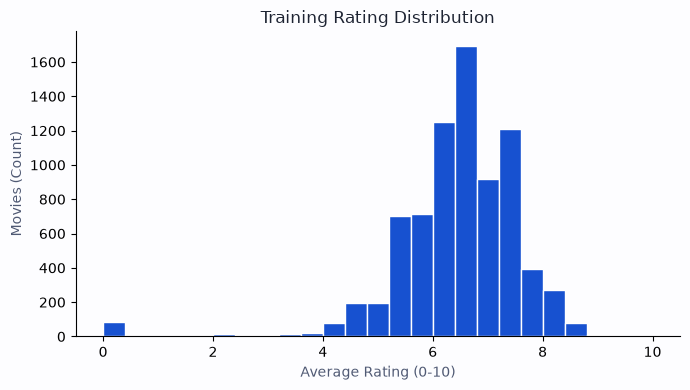

In [225]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

rating = pd.to_numeric(
    train_set["Vote_Average"],
    errors="coerce"
)

ax.hist(
    rating.dropna(),
    bins=25,
    color="#1751D0",
    edgecolor="white"
)

ax.set(
    title="Training Rating Distribution",
    xlabel="Average Rating (0-10)",
    ylabel="Movies (Count)"
)

fig.tight_layout()
plt.show()
plt.close(fig)

#### 개봉 연도와 평점

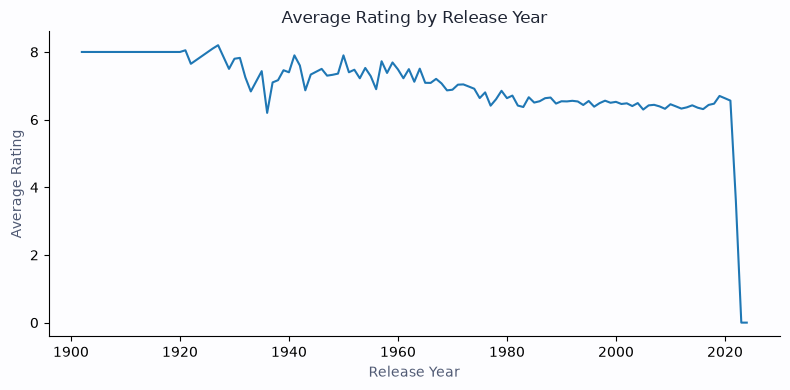

In [226]:
year_rating = (
    train_set
    .assign(
        Release_Year=pd.to_datetime(
            train_set["Release_Date"],
            format="%d/%m/%Y",
            errors="coerce"
        ).dt.year,
        Vote_Average=pd.to_numeric(
            train_set["Vote_Average"],
            errors="coerce"
        )
    )
    .dropna(subset=["Release_Year", "Vote_Average"])
    .groupby("Release_Year")["Vote_Average"]
    .mean()
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    year_rating.index,
    year_rating.values
)

ax.set(
    title="Average Rating by Release Year",
    xlabel="Release Year",
    ylabel="Average Rating"
)

fig.tight_layout()
plt.show()
plt.close(fig)

#### 장르별 평균 평점

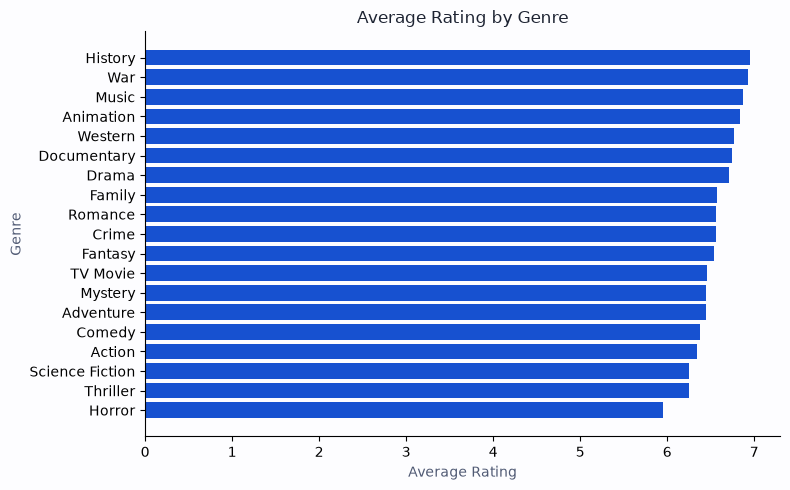

In [227]:
genre_rating = (
    train_set[["Genre", "Vote_Average"]]
    .assign(
        Vote_Average=lambda x: pd.to_numeric(
            x["Vote_Average"],
            errors="coerce"
        ),
        Genre=lambda x: x["Genre"]
        .fillna("")
        .str.split(",")
    )
    .dropna(subset=["Vote_Average"])
    .explode("Genre")
)

genre_rating["Genre"] = genre_rating["Genre"].str.strip()

genre_rating = (
    genre_rating[genre_rating["Genre"] != ""]
    .groupby("Genre")["Vote_Average"]
    .mean()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    genre_rating.index,
    genre_rating.values,
    color="#1751D0"
)

ax.set(
    title="Average Rating by Genre",
    xlabel="Average Rating",
    ylabel="Genre"
)

fig.tight_layout()
plt.show()
plt.close(fig)

#### 언어별 평균 평점

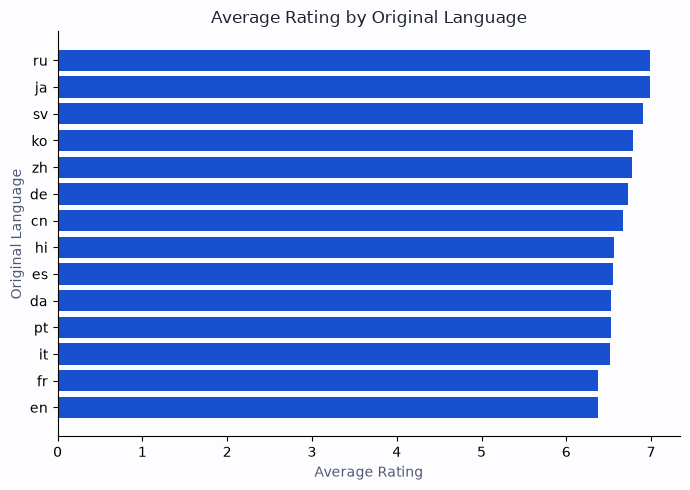

In [228]:
language_rating = (
    train_set
    .assign(
        Vote_Average=lambda x: pd.to_numeric(
            x["Vote_Average"],
            errors="coerce"
        )
    )
    .dropna(subset=["Original_Language", "Vote_Average"])
    .groupby("Original_Language")["Vote_Average"]
    .agg(["mean", "count"])
    .query("count >= 20")
    .sort_values("mean")
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.barh(
    language_rating.index,
    language_rating["mean"],
    color="#1751D0"
)

ax.set(
    title="Average Rating by Original Language",
    xlabel="Average Rating",
    ylabel="Original Language"
)

fig.tight_layout()
plt.show()
plt.close(fig)

## 5. 데이터 정제

#### 데이터 타입 변환

In [229]:
train_set = train_set.copy()
test_set = test_set.copy()

for df in [train_set, test_set]:
    df["Vote_Average"] = pd.to_numeric(df["Vote_Average"], errors="coerce")
    df["Release_Date"] = pd.to_datetime( df["Release_Date"], format="%d/%m/%Y", errors="coerce")

#### 파생 변수 생성

In [230]:
for df in [train_set, test_set]:
    df["Release_Year"] = (df["Release_Date"].dt.year)
    df["Release_Month"] = (df["Release_Date"].dt.month)

#### 데이터에 기재된 모든 장르 사용

In [231]:
train_genres = (
    train_set["Genre"]
    .fillna("")
    .str.split(",")
    .explode()
    .str.strip()
)

genre_cols = sorted(
    train_genres[
        train_genres != ""
    ].unique()
)

print("사용할 장르:")
print(genre_cols)

for genre in genre_cols:

    train_set[f"Genre_{genre}"] = (
        train_set["Genre"]
        .fillna("")
        .str.split(",")
        .apply(
            lambda x: int(
                genre in [g.strip() for g in x]
            )
        )
    )

    test_set[f"Genre_{genre}"] = (
        test_set["Genre"]
        .fillna("")
        .str.split(",")
        .apply(
            lambda x: int(
                genre in [g.strip() for g in x]
            )
        )
    )

사용할 장르:
['Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'History', 'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'TV Movie', 'Thriller', 'War', 'Western']


#### 입력 변수 설정

In [232]:
num_cols = [
    "Release_Year",
    "Release_Month",
]

cat_cols = ["Original_Language"]

genre_feature_cols = [
    f"Genre_{genre}"
    for genre in genre_cols
]

features = num_cols + cat_cols + genre_feature_cols

#### 목표 변수 결측값 제거

In [233]:
train_set = train_set.dropna(subset=["Vote_Average"])
test_set = test_set.dropna(subset=["Vote_Average"])

#### x, y 분리

In [234]:
X_train = train_set[features]
y_train = train_set["Vote_Average"]

X_test = test_set[features]
y_test = test_set["Vote_Average"]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (7862, 22)
X_test : (1964, 22)


In [235]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols),
    ("genre", "passthrough", genre_feature_cols)
])

## 6. 모델 학습

In [236]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=SEED),
}